# 데이터 탐색과 시각화

독창적 가상 데이터와 자체 연습 문항입니다. 제공 샘플의 흐름을 참고했으며 원문 복제가 아닙니다.

14문항 · 파트 연습 · 힌트 사용 가능

CSV 두 개와 노트북을 같은 폴더에 두세요. 커널 재시작 → 전체 실행 → 저장한 뒤 사이트에 제출하세요. 각 답안 다음 검증 셀은 실행 결과를 검사합니다. 검증 셀을 바꾸면 점수 신뢰도가 사라집니다. 공식 점수 예측이 아닌 자체 연습 점수입니다.

데이터: ticket_id 식별번호, created_at 접수일시, issue_type 문의유형, contact_channel 채널, membership_tier 등급, tenure_months 가입개월, monthly_spend 월금액(원), previous_tickets 과거 문의 수, wait_minutes 대기분, past_satisfaction_score 과거만족도(1~5), escalated 이관여부(0/1), resolution_hours 해결시간(시간). resolution_hours는 분류 입력에서 제외합니다.

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix, mean_absolute_error
SET_ID='part-eda'
DATA_FILE="practice.csv"
MEMBERS_FILE="members.csv"
MODEL_FILE="best_part-eda.keras"

from pathlib import Path
import json as _json
from IPython.display import display as _display
_raw = pd.read_csv(DATA_FILE)
_grade_results = []
def _filled(d):
    x=d.copy()
    cols=['wait_minutes','past_satisfaction_score','monthly_spend']
    x[cols]=x[cols].fillna(x[cols].median())
    x['contact_channel']=x.contact_channel.fillna(x.contact_channel.mode().iloc[0])
    return x
def _plot_ok(fig,h,k1,k2,title,ylabel,labels=None):
    a=fig.axes[0]
    ls=a.get_lines()
    labels=labels or [k1,k2]
    return (len(ls)==2 and a.get_title()==title and a.get_xlabel()=='Epoch' and a.get_ylabel()==ylabel
      and np.allclose(ls[0].get_ydata(),h.history[k1]) and np.allclose(ls[1].get_ydata(),h.history[k2])
      and a.get_legend() is not None and [t.get_text() for t in a.get_legend().get_texts()]==labels)
def _grade_q(number,checks):
    items=[]
    for label,expr in checks:
        try:
            ok=bool(eval(expr,globals()))
            items.append({'label':label,'passed':ok,'detail':'검사 통과' if ok else '실행 결과가 지시와 다릅니다. 변수명·조건·파라미터를 확인하세요.'})
        except Exception as e:
            items.append({'label':label,'passed':False,'detail':type(e).__name__+': '+str(e)[:180]})
    report={'schema':'aice-lab-v1','setId':SET_ID,'question':number,'checks':items}
    _grade_results.append(report)
    _display({'application/json':report},raw=True)


## 1. 데이터 로드 (7점)

pandas를 pd로 불러오고 DATA_FILE을 data에 읽으세요. 처음 4행을 출력하세요.

In [72]:
# 여기에 답안코드를 작성하고 실행하세요.
import pandas as pd

data = pd.read_csv(DATA_FILE)

data.head(4)

,ticket_id,created_at,issue_type,contact_channel,membership_tier,tenure_months,monthly_spend,previous_tickets,wait_minutes,past_satisfaction_score,escalated,resolution_hours
0,T1400-0,2026-02-05 13:00:00,Technical,Phone,Silver,28,57300.0,3,15.3,3.1,0,10.91
1,T1400-1,2026-04-21 03:00:00,Payment,Email,Basic,12,26200.0,0,21.5,2.9,0,4.96
2,T1400-2,2026-03-25 11:00:00,Product,Email,Gold,20,28100.0,5,7.9,2.7,0,8.47
3,T1400-3,2026-05-28 11:00:00,Account,Email,Silver,42,54100.0,0,NaN,4.2,0,6.64


In [73]:
_grade_q(1, [['원본 데이터가 정확히 로드됨', 'isinstance(data,pd.DataFrame) and data.equals(_raw)']])

## 2. 구조와 자료형 (7점)

행·열 개수를 shape_answer에, 컬럼별 자료형을 dtype_answer에 저장하세요.

In [74]:
# 여기에 답안코드를 작성하고 실행하세요.
shape_answer = data.shape

dtype_answer = data.dtypes


In [75]:
_grade_q(2, [['행·열 개수', 'shape_answer == _raw.shape'], ['자료형', 'dtype_answer.equals(_raw.dtypes)']])

## 3. 결측치 합계 (7점)

컬럼별 결측치 개수를 missing_by_col에, 전체 결측치 개수를 missing_total에 저장하세요.

In [76]:
# 여기에 답안코드를 작성하고 실행하세요.
missing_by_col = data.isna().sum()
missing_total = missing_by_col.sum()

In [77]:
_grade_q(3, [['컬럼별 개수', 'missing_by_col.equals(_raw.isna().sum())'], ['전체 개수', 'missing_total == _raw.isna().sum().sum()']])

## 4. 범주 개수 (7점)

issue_type의 범주별 개수를 issue_counts에 저장하세요. 최빈 범주를 most_issue에 저장하세요.

In [78]:
# 여기에 답안코드를 작성하고 실행하세요.
issue_counts = data["issue_type"].value_counts()
most_issue = data["issue_type"].mode().iloc[0]

In [79]:
_grade_q(4, [['범주 개수', 'issue_counts.equals(_raw.issue_type.value_counts())'], ['최빈 범주', 'most_issue == _raw.issue_type.value_counts().idxmax()']])

## 5. 조건 선택 (7점)

wait_minutes가 30 이상인 행만 slow에 저장하세요. 원본을 수정하지 마세요.

In [80]:
# 여기에 답안코드를 작성하고 실행하세요.
slow = data[data["wait_minutes"]>=30]

In [81]:
_grade_q(5, [['조건에 맞는 행', 'slow.equals(_raw.loc[_raw.wait_minutes>=30])']])

## 6. 두 조건 AND (7점)

previous_tickets가 2 이상이고 escalated가 1인 행을 repeat_high에 저장하세요.

In [82]:
# 여기에 답안코드를 작성하고 실행하세요.
repeat_high = data[(data["previous_tickets"]>=2)&(data["escalated"]==1)]

In [83]:
_grade_q(6, [['AND 조건', 'repeat_high.equals(_raw.loc[(_raw.previous_tickets>=2)&(_raw.escalated==1)])']])

## 7. 두 조건 OR (7점)

Payment 또는 Account 문의만 billing에 저장하세요.

In [84]:
# 여기에 답안코드를 작성하고 실행하세요.
billing = data[(data["issue_type"]=="Payment")|(data["issue_type"]=="Account")]

In [85]:
_grade_q(7, [['OR 선택', 'billing.equals(_raw.loc[_raw.issue_type.isin(["Payment","Account"])])']])

## 8. 그룹 평균 (7점)

membership_tier별 monthly_spend 평균을 tier_mean에 저장하세요.

In [86]:
# 여기에 답안코드를 작성하고 실행하세요.
tier_mean = data.groupby("membership_tier")["monthly_spend"].mean()

In [87]:
_grade_q(8, [['그룹 평균', 'np.allclose(tier_mean.sort_index(),_raw.groupby("membership_tier").monthly_spend.mean().sort_index())']])

## 9. 정렬과 위치 (7점)

wait_minutes를 내림차순 정렬한 후 첫 행의 ticket_id를 longest_id에 저장하세요.

In [88]:
# 여기에 답안코드를 작성하고 실행하세요.
longest_id = data.sort_values("wait_minutes",ascending=False).iloc[0].iloc[0]

longest_id

'T1400-577'

In [89]:
_grade_q(9, [['최댓값 행 식별', 'longest_id in _raw.loc[_raw.wait_minutes==_raw.wait_minutes.max(),"ticket_id"].tolist()']])

## 10. 중복 확인 (7점)

완전히 동일한 중복 행의 개수를 duplicate_count에 저장하세요.

In [90]:
# 여기에 답안코드를 작성하고 실행하세요.
duplicate_count = data.duplicated().sum()

In [91]:
_grade_q(10, [['중복 행 수', 'duplicate_count == 5']])

## 11. 날짜 특성 (7점)

원본을 복사한 dated를 만들고 created_at을 datetime으로 변환하세요. hour와 dayofweek 컬럼을 추가하세요.

In [92]:
# 여기에 답안코드를 작성하고 실행하세요.
dated = data.copy()

dated["created_at"] = pd.to_datetime(dated["created_at"])

dated["hour"] = dated["created_at"].dt.hour
dated["dayofweek"] = dated["created_at"].dt.day_of_week

In [93]:
_grade_q(11, [['시간 추출', 'np.array_equal(dated.hour,pd.to_datetime(_raw.created_at).dt.hour)'], ['요일 추출', 'np.array_equal(dated.dayofweek,pd.to_datetime(_raw.created_at).dt.dayofweek)']])

## 12. countplot (7점)

issue_type의 분포를 countplot으로 표시하세요. 제목은 Issue Count. Figure를 fig_count에 저장하세요.

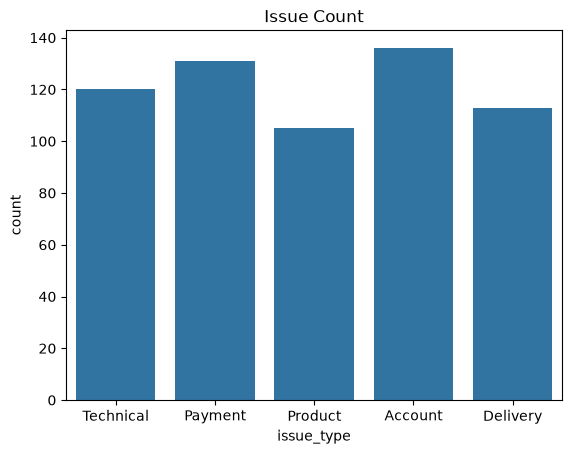

In [94]:
# 여기에 답안코드를 작성하고 실행하세요.
import matplotlib.pyplot as plt
import seaborn as sns

fig_count = plt.figure()

sns.countplot(data=data, x="issue_type")

plt.title("Issue Count")
plt.show()

In [95]:
_grade_q(12, [['제목과 막대 개수', 'fig_count.axes[0].get_title()=="Issue Count" and len(fig_count.axes[0].patches)==_raw.issue_type.nunique()']])

## 13. histplot (7점)

wait_minutes의 히스토그램을 20구간으로 그리세요. Figure를 fig_hist에 저장하세요.

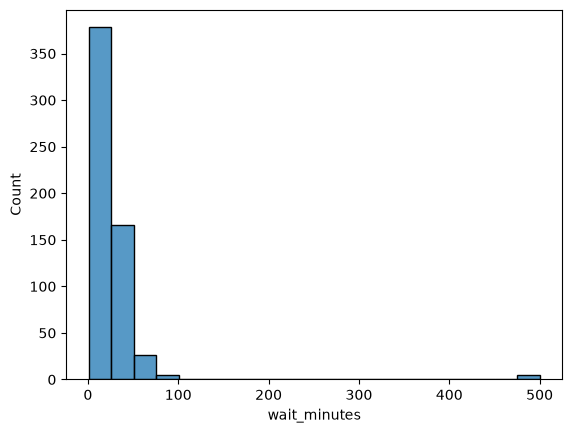

In [96]:
# 여기에 답안코드를 작성하고 실행하세요.
fig_hist = plt.figure()

sns.histplot(data=data, x="wait_minutes", bins=20)
plt.show()

In [97]:
_grade_q(13, [['히스토그램 구간', 'len(fig_hist.axes[0].patches)==20'], ['축 이름', 'fig_hist.axes[0].get_xlabel()=="wait_minutes"']])

## 14. 피벗 집계 (9점)

membership_tier를 행, contact_channel을 열로 하고 monthly_spend의 평균을 계산한 pivot_answer를 만드세요.

In [98]:
# 여기에 답안코드를 작성하고 실행하세요.
pivot_answer = pd.pivot_table(data=data, index="membership_tier", columns="contact_channel", values="monthly_spend", aggfunc="mean")
pivot_answer

contact_channel,Chat,Email,Phone
membership_tier,,,
Basic,49512.698413,51824.637681,54586.666667
Gold,43940.000000,48701.754386,53261.016949
Silver,52490.909091,44384.415584,54009.677419


In [99]:
_grade_q(14, [['피벗 결과', 'pivot_answer.equals(pd.pivot_table(_raw,index="membership_tier",columns="contact_channel",values="monthly_spend",aggfunc="mean"))']])

## 제출
검증 결과를 포함한 상태로 저장하세요. VS Code에서 실행이 중단되면 오류를 고친 뒤 다시 전체 실행하세요. 설치가 필요하면 사이트의 환경 설정 안내를 확인하세요.